# 05_OULAD_Analyse_Temporelle.ipynb — ANALYSE TEMPORELLE COMPARATIVE

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. SETUP

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
import os
import joblib
warnings.filterwarnings('ignore')

from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score
from sklearn.model_selection import GroupKFold
from scipy.stats import pearsonr

base_path      = '/content/drive/MyDrive/MOOC_Recommandation_Adaptative/data/raw/OULAD'
processed_path = f"{base_path}/processed"
results_dir    = '/content/drive/MyDrive/MOOC_Recommandation_Adaptative/results'
metrics_dir    = f"{results_dir}/metrics"
plots_dir      = f"{results_dir}/plots"
temporal_dir   = f"{results_dir}/temporal"

for d in [temporal_dir]:
    os.makedirs(d, exist_ok=True)

CUTOFFS      = [14, 28, 42]
RANDOM_STATE = 42

print("Setup terminé.")

Setup terminé.


# 2. CHARGEMENT DES RÉSULTATS CV EXISTANTS

In [ ]:
print("\n" + "="*70)
print("  CHARGEMENT DES RÉSULTATS CROSS-VALIDATION")
print("="*70)

# Charger les résultats détaillés du notebook 03
df_cv = pd.read_csv(f"{metrics_dir}/cv_results_detailed.csv")
df_summary = pd.read_csv(f"{metrics_dir}/cv_results_summary.csv")

print(f"  Résultats CV chargés : {len(df_cv)} entrées")
print(f"  Modèles : {df_cv['model'].unique().tolist()}")
print(f"  Cutoffs : {df_cv['cutoff'].unique().tolist()}")
print(f"  Folds   : {df_cv['fold'].nunique()}")


  CHARGEMENT DES RÉSULTATS CROSS-VALIDATION
  Résultats CV chargés : 90 entrées
  Modèles : ['Logistic Regression', 'Random Forest', 'XGBoost']
  Cutoffs : [14, 28, 42]
  Folds   : 10


# 3. ANALYSE DU TRADE-OFF PRÉCOCITÉ VS PRÉCISION

In [ ]:
print("\n" + "="*70)
print("  ANALYSE TRADE-OFF PRÉCOCITÉ VS PRÉCISION")
print("="*70)

# Extraire AUC XGBoost par cutoff
xgb_summary = df_summary[df_summary['model'] == 'XGBoost'].sort_values('cutoff')

print(f"\n  XGBoost — Performance par cutoff :")
print(f"  {'Cutoff':<10} {'AUC':<20} {'F1':<20} {'Recall':<20} {'Precision'}")
print("  " + "-"*80)
for _, row in xgb_summary.iterrows():
    print(f"  Jour {int(row['cutoff']):<7} "
          f"{row['auc_mean']:.4f} ± {row['auc_std']:.4f}   "
          f"{row['f1_mean']:.4f} ± {row['f1_std']:.4f}   "
          f"{row['recall_mean']:.4f} ± {row['recall_std']:.4f}   "
          f"{row['precision_mean']:.4f} ± {row['precision_std']:.4f}")

# Calcul du coût de prédire plus tôt
best_auc = xgb_summary['auc_mean'].max()
print(f"\n  Coût de prédire plus tôt (vs meilleur cutoff J42) :")
for _, row in xgb_summary.iterrows():
    cost = best_auc - row['auc_mean']
    days_earlier = 42 - int(row['cutoff'])
    print(f"  Jour {int(row['cutoff']):<5} → coût AUC : -{cost:.4f} | "
          f"Avance temporelle : +{days_earlier} jours d'intervention")


  ANALYSE TRADE-OFF PRÉCOCITÉ VS PRÉCISION

  XGBoost — Performance par cutoff :
  Cutoff     AUC                  F1                   Recall               Precision
  --------------------------------------------------------------------------------
  Jour 14      0.8042 ± 0.0069   0.6289 ± 0.0081   0.6483 ± 0.0095   0.6109 ± 0.0129
  Jour 28      0.8497 ± 0.0061   0.6909 ± 0.0094   0.6955 ± 0.0096   0.6865 ± 0.0139
  Jour 42      0.8600 ± 0.0061   0.6998 ± 0.0120   0.7099 ± 0.0132   0.6901 ± 0.0138

  Coût de prédire plus tôt (vs meilleur cutoff J42) :
  Jour 14    → coût AUC : -0.0558 | Avance temporelle : +28 jours d'intervention
  Jour 28    → coût AUC : -0.0103 | Avance temporelle : +14 jours d'intervention
  Jour 42    → coût AUC : -0.0000 | Avance temporelle : +0 jours d'intervention


# 4. ANALYSE DE LA COUVERTURE DES DONNÉES PAR CUTOFF

In [ ]:
print("\n" + "="*70)
print("  ANALYSE COUVERTURE DES DONNÉES PAR CUTOFF")
print("="*70)

coverage_stats = []

for cutoff in CUTOFFS:
    df = pd.read_csv(f"{processed_path}/oulad_features_cutoff_{cutoff}.csv")

    n_total         = len(df)
    n_with_vle      = (df['total_clicks'] > 0).sum() if 'total_clicks' in df.columns else 0
    n_with_assess   = (df['num_submitted_assessments'] > 0).sum()
    n_with_both     = ((df['total_clicks'] > 0) & (df['num_submitted_assessments'] > 0)).sum() \
                      if 'total_clicks' in df.columns else 0
    pct_vle         = n_with_vle / n_total * 100
    pct_assess      = n_with_assess / n_total * 100
    pct_both        = n_with_both / n_total * 100

    # Richesse des features — moyenne des clics par étudiant actif
    avg_clicks = df[df['total_clicks'] > 0]['total_clicks'].mean() \
                 if 'total_clicks' in df.columns else 0

    coverage_stats.append({
        'cutoff'        : cutoff,
        'n_total'       : n_total,
        'n_with_vle'    : n_with_vle,
        'n_with_assess' : n_with_assess,
        'n_with_both'   : n_with_both,
        'pct_vle'       : pct_vle,
        'pct_assess'    : pct_assess,
        'pct_both'      : pct_both,
        'avg_clicks'    : avg_clicks,
    })

    print(f"\n  Cutoff Jour {cutoff} :")
    print(f"    Étudiants total           : {n_total:,}")
    print(f"    Avec données VLE          : {n_with_vle:,} ({pct_vle:.1f}%)")
    print(f"    Avec évaluations          : {n_with_assess:,} ({pct_assess:.1f}%)")
    print(f"    Avec les deux             : {n_with_both:,} ({pct_both:.1f}%)")
    print(f"    Clics moyens (actifs)     : {avg_clicks:.1f}")

df_coverage = pd.DataFrame(coverage_stats)


  ANALYSE COUVERTURE DES DONNÉES PAR CUTOFF

  Cutoff Jour 14 :
    Étudiants total           : 32,593
    Avec données VLE          : 28,081 (86.2%)
    Avec évaluations          : 4,580 (14.1%)
    Avec les deux             : 4,352 (13.4%)
    Clics moyens (actifs)     : 220.6

  Cutoff Jour 28 :
    Étudiants total           : 32,593
    Avec données VLE          : 28,792 (88.3%)
    Avec évaluations          : 22,351 (68.6%)
    Avec les deux             : 21,889 (67.2%)
    Clics moyens (actifs)     : 350.6

  Cutoff Jour 42 :
    Étudiants total           : 32,593
    Avec données VLE          : 28,973 (88.9%)
    Avec évaluations          : 24,545 (75.3%)
    Avec les deux             : 24,063 (73.8%)
    Clics moyens (actifs)     : 441.9


# 5. ANALYSE DE LA DISTRIBUTION DES DROPOUT SCORES PAR CUTOFF

In [ ]:
print("\n" + "="*70)
print("  DISTRIBUTION DES DROPOUT SCORES PAR CUTOFF")
print("="*70)

# Charger le modèle final et recalculer les scores pour J14 et J28
# (J42 est déjà disponible)
xgb_model = joblib.load(f"{results_dir}/models/xgboost_final_cutoff42.joblib")

dropout_by_cutoff = {}

for cutoff in CUTOFFS:
    df = pd.read_csv(f"{processed_path}/oulad_features_cutoff_{cutoff}.csv")

    # Préparer features (identique notebook 03)
    drop_cols = ['id_student', 'final_result', 'is_withdrawn', 'cutoff_day']
    cat_cols  = [c for c in df.select_dtypes(include='object').columns
                 if c not in drop_cols]
    df_enc    = pd.get_dummies(df, columns=cat_cols, drop_first=True)

    num_cols = df_enc.select_dtypes(include=np.number).columns
    for col in num_cols:
        df_enc[col] = df_enc[col].fillna(df_enc[col].median())

    X = df_enc.drop(columns=drop_cols, errors='ignore')
    X.columns = (X.columns
                 .str.replace('[', '', regex=False).str.replace(']', '', regex=False)
                 .str.replace('<', '', regex=False).str.replace(' ', '_', regex=False)
                 .str.replace('-', '_', regex=False))

    # Aligner avec le modèle
    expected = xgb_model.get_booster().feature_names
    for col in expected:
        if col not in X.columns:
            X[col] = 0
    X = X[[c for c in expected if c in X.columns]]

    scores = xgb_model.predict_proba(X)[:, 1]
    y_true = df['is_withdrawn'].values

    dropout_by_cutoff[cutoff] = {
        'scores' : scores,
        'y_true' : y_true,
        'auc'    : roc_auc_score(y_true, scores)
    }

    # Distribution par niveau de risque
    high   = (scores > 0.7).sum()
    medium = ((scores >= 0.4) & (scores <= 0.7)).sum()
    low    = (scores < 0.4).sum()

    print(f"\n  Cutoff Jour {cutoff} :")
    print(f"    AUC             : {dropout_by_cutoff[cutoff]['auc']:.4f}")
    print(f"    Risque élevé    : {high:,} ({100*high/len(scores):.1f}%)")
    print(f"    Risque modéré   : {medium:,} ({100*medium/len(scores):.1f}%)")
    print(f"    Risque faible   : {low:,} ({100*low/len(scores):.1f}%)")


  DISTRIBUTION DES DROPOUT SCORES PAR CUTOFF

  Cutoff Jour 14 :
    AUC             : 0.7222
    Risque élevé    : 24,118 (74.0%)
    Risque modéré   : 6,045 (18.5%)
    Risque faible   : 2,430 (7.5%)

  Cutoff Jour 28 :
    AUC             : 0.8311
    Risque élevé    : 10,949 (33.6%)
    Risque modéré   : 14,869 (45.6%)
    Risque faible   : 6,775 (20.8%)

  Cutoff Jour 42 :
    AUC             : 0.9080
    Risque élevé    : 7,136 (21.9%)
    Risque modéré   : 5,824 (17.9%)
    Risque faible   : 19,633 (60.2%)


# 6. RECOMMANDATION PRATIQUE — MEILLEUR CUTOFF POUR DÉPLOIEMENT

In [ ]:
print("\n" + "="*70)
print("  RECOMMANDATION PRATIQUE — CUTOFF OPTIMAL")
print("="*70)

# Score composite : AUC normalisé × avance temporelle normalisée
aucs    = np.array([xgb_summary[xgb_summary['cutoff'] == c]['auc_mean'].values[0]
                    for c in CUTOFFS])
advances = np.array([42 - c for c in CUTOFFS])  # jours d'avance vs J42

auc_norm     = (aucs - aucs.min()) / (aucs.max() - aucs.min())
advance_norm = (advances - advances.min()) / (advances.max() - advances.min() + 1e-9)

# Deux scénarios
print("\n  Scénario A — Priorité performance (poids AUC=0.7, avance=0.3) :")
score_a = 0.7 * auc_norm + 0.3 * advance_norm
for i, c in enumerate(CUTOFFS):
    print(f"    Jour {c} : score = {score_a[i]:.4f} {'← OPTIMAL' if score_a[i] == score_a.max() else ''}")

print("\n  Scénario B — Priorité précocité (poids AUC=0.3, avance=0.7) :")
score_b = 0.3 * auc_norm + 0.7 * advance_norm
for i, c in enumerate(CUTOFFS):
    print(f"    Jour {c} : score = {score_b[i]:.4f} {'← OPTIMAL' if score_b[i] == score_b.max() else ''}")

print("\n  Scénario C — Équilibre (poids AUC=0.5, avance=0.5) :")
score_c = 0.5 * auc_norm + 0.5 * advance_norm
for i, c in enumerate(CUTOFFS):
    print(f"    Jour {c} : score = {score_c[i]:.4f} {'← OPTIMAL' if score_c[i] == score_c.max() else ''}")


  RECOMMANDATION PRATIQUE — CUTOFF OPTIMAL

  Scénario A — Priorité performance (poids AUC=0.7, avance=0.3) :
    Jour 14 : score = 0.3000 
    Jour 28 : score = 0.7209 ← OPTIMAL
    Jour 42 : score = 0.7000 

  Scénario B — Priorité précocité (poids AUC=0.3, avance=0.7) :
    Jour 14 : score = 0.7000 ← OPTIMAL
    Jour 28 : score = 0.5947 
    Jour 42 : score = 0.3000 

  Scénario C — Équilibre (poids AUC=0.5, avance=0.5) :
    Jour 14 : score = 0.5000 
    Jour 28 : score = 0.6578 ← OPTIMAL
    Jour 42 : score = 0.5000 


# 7. VISUALISATIONS PUBLICATION-READY


  Génération des visualisations...


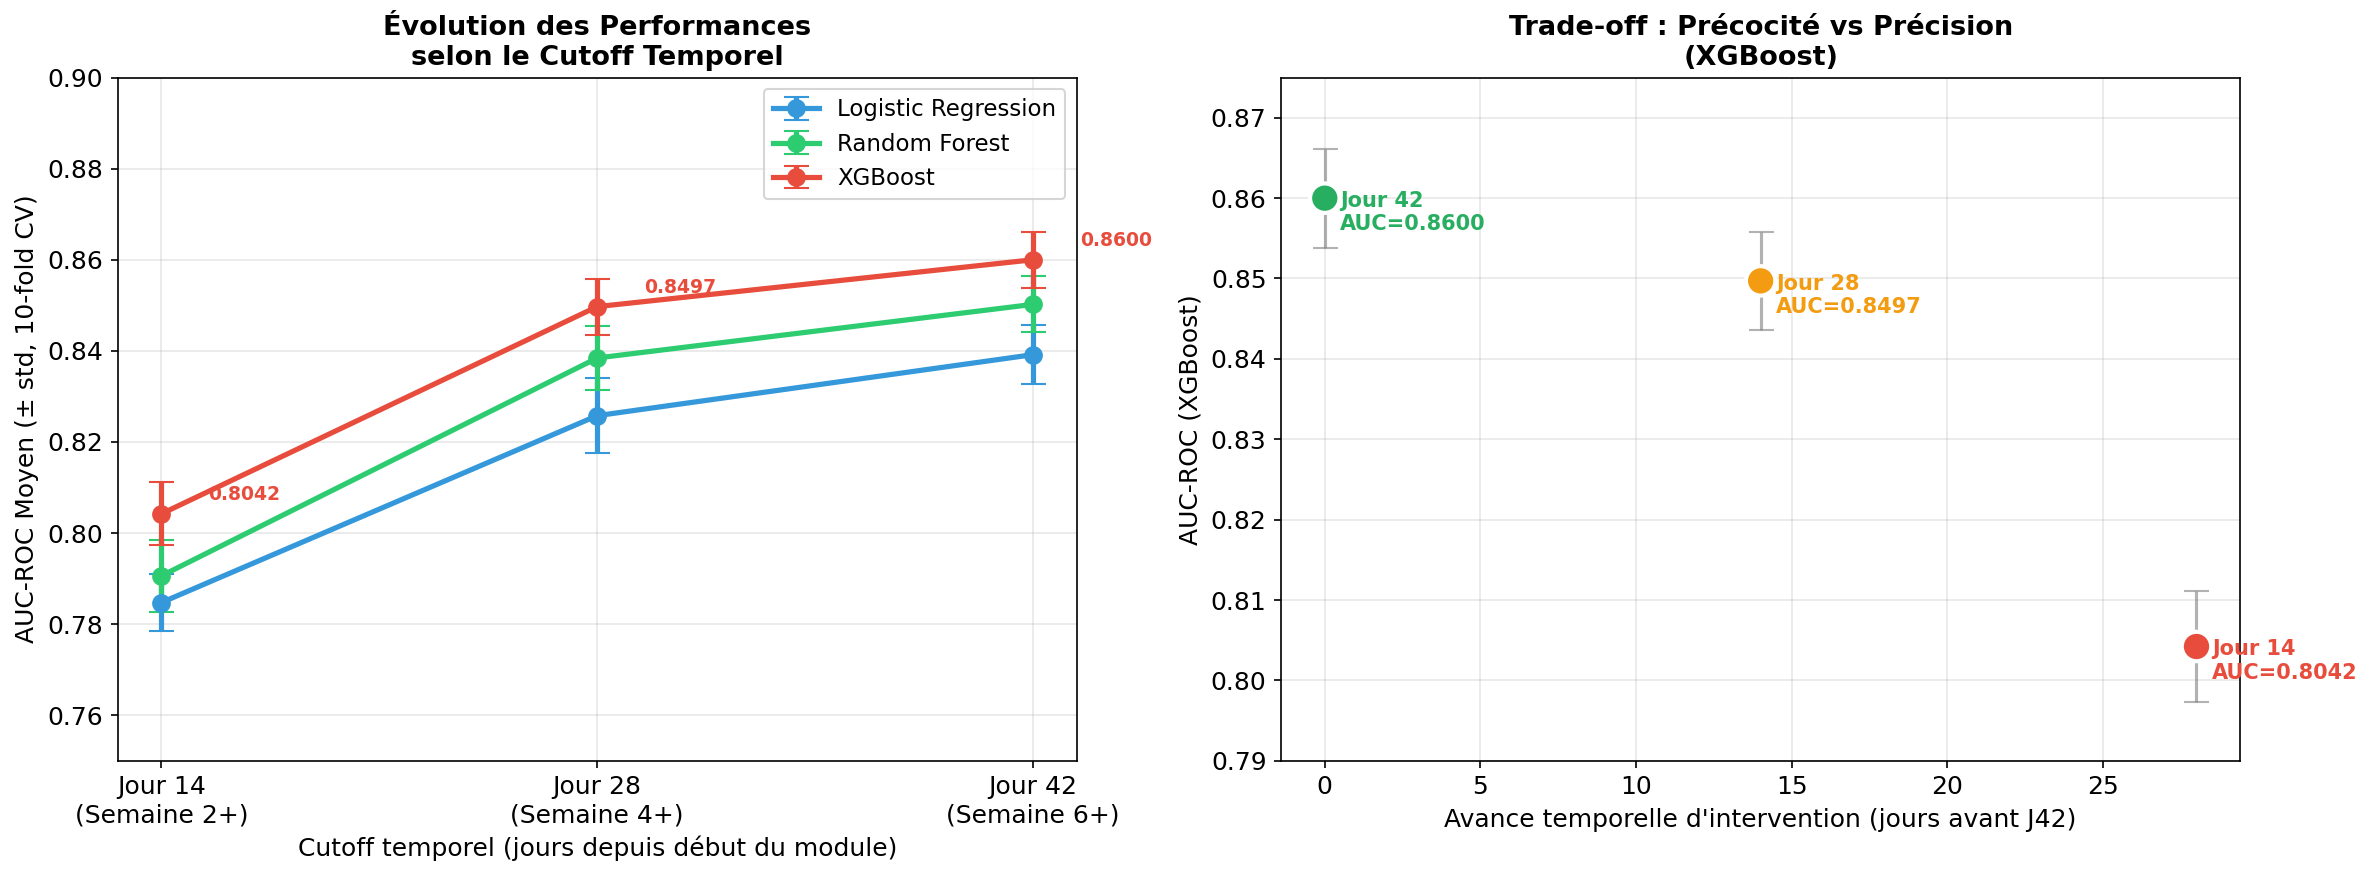

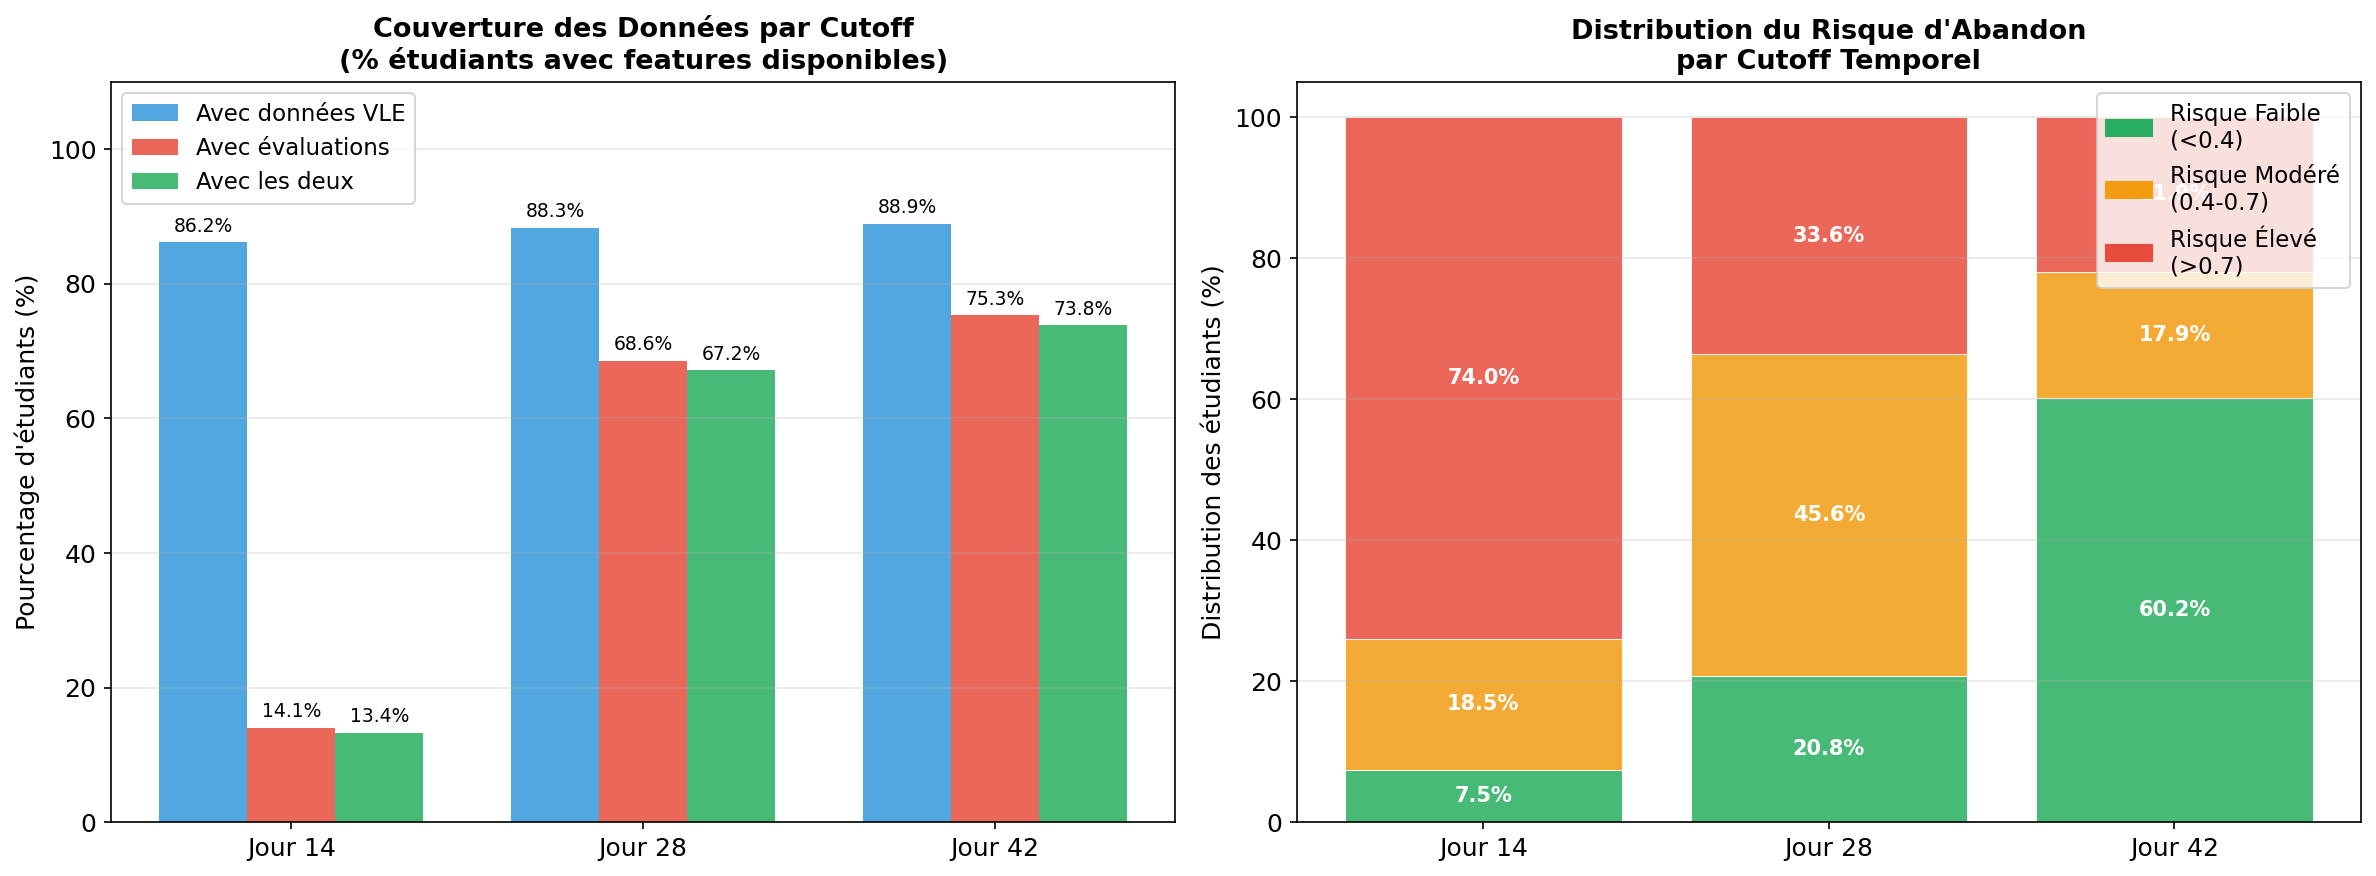

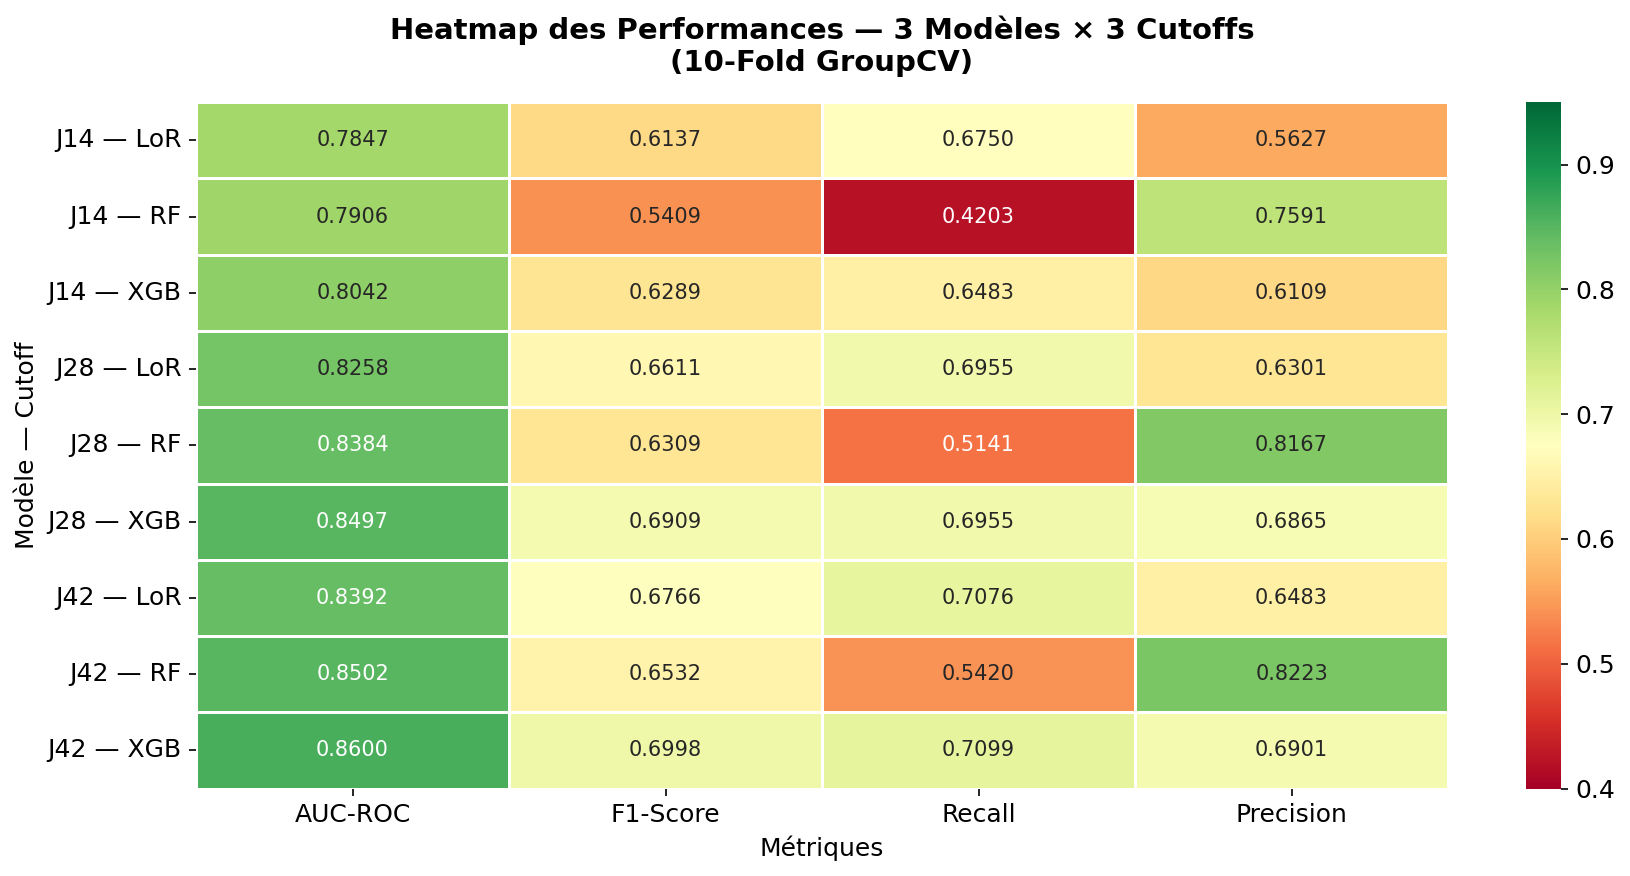

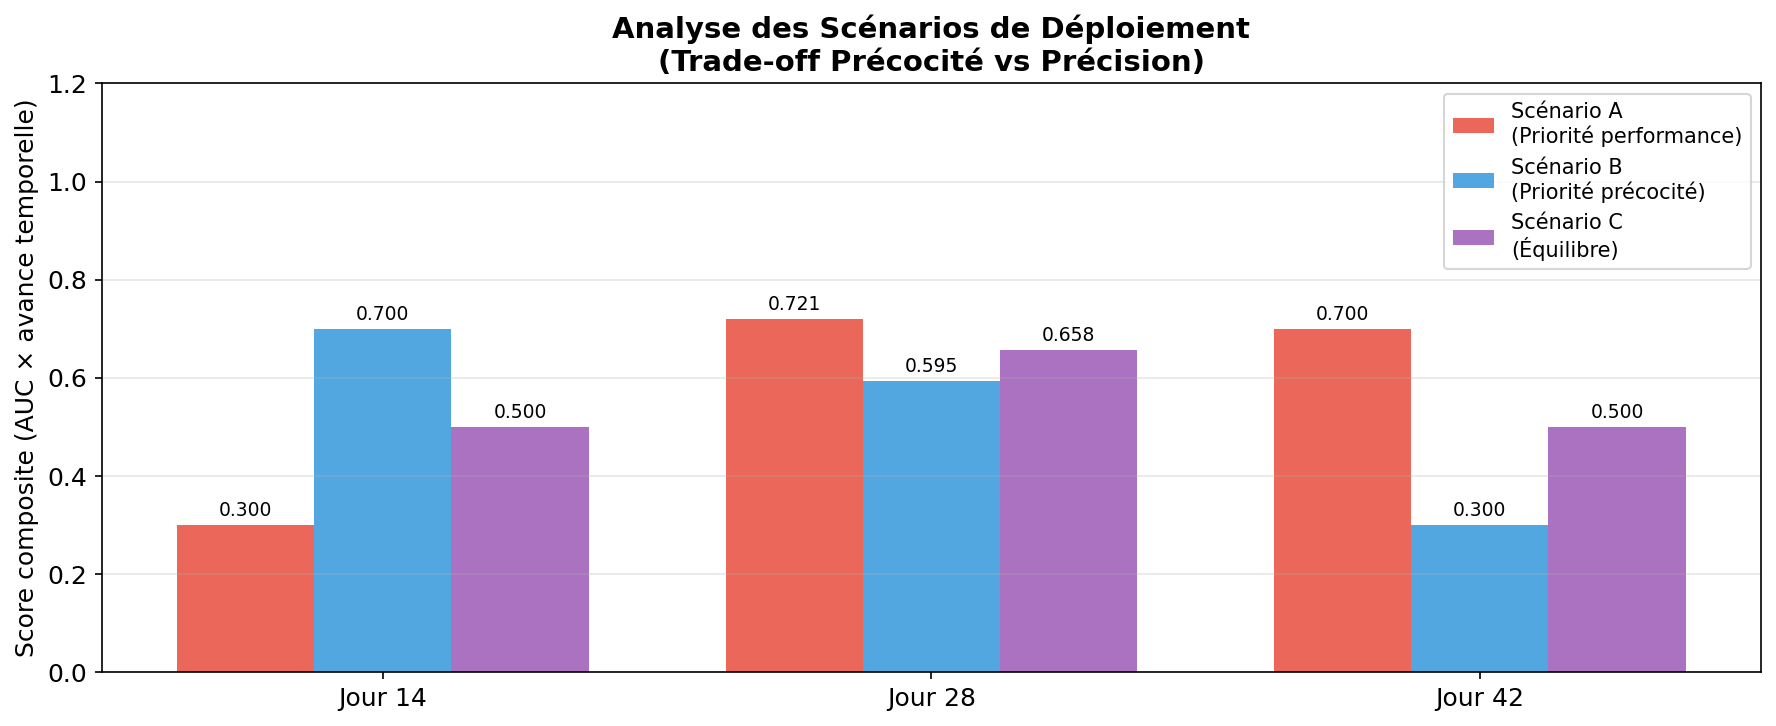

In [ ]:
print("\n  Génération des visualisations...")

plt.rcParams.update({
    'font.family'  : 'DejaVu Sans',
    'font.size'    : 12,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 11,
    'figure.dpi'   : 150
})

colors_model = {
    'Logistic Regression': '#3498DB',
    'Random Forest'      : '#2ECC71',
    'XGBoost'            : '#E74C3C'
}

# ---- FIGURE 1 : Evolution AUC par cutoff et modèle ----
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for model_name, color in colors_model.items():
    sub = df_summary[df_summary['model'] == model_name].sort_values('cutoff')
    axes[0].errorbar(
        sub['cutoff'], sub['auc_mean'], yerr=sub['auc_std'],
        marker='o', linewidth=2.5, markersize=8,
        color=color, capsize=6, label=model_name
    )

axes[0].set_xlabel('Cutoff temporel (jours depuis début du module)', fontsize=12)
axes[0].set_ylabel('AUC-ROC Moyen (± std, 10-fold CV)', fontsize=12)
axes[0].set_title('Évolution des Performances\nselon le Cutoff Temporel', fontweight='bold')
axes[0].set_xticks(CUTOFFS)
axes[0].set_xticklabels([f'Jour {c}\n(Semaine {c//7}+)' for c in CUTOFFS])
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0.75, 0.90])

# Annotations coût-bénéfice
for i, c in enumerate(CUTOFFS):
    auc = xgb_summary[xgb_summary['cutoff'] == c]['auc_mean'].values[0]
    axes[0].annotate(f'{auc:.4f}',
        xy=(c, auc), xytext=(c+1.5, auc+0.003),
        fontsize=9, color='#E74C3C', fontweight='bold')

# ---- FIGURE 1b : Trade-off AUC vs Avance temporelle ----
xgb_aucs = [xgb_summary[xgb_summary['cutoff'] == c]['auc_mean'].values[0] for c in CUTOFFS]
xgb_stds = [xgb_summary[xgb_summary['cutoff'] == c]['auc_std'].values[0]  for c in CUTOFFS]
days_advance = [42 - c for c in CUTOFFS]

sc = axes[1].scatter(days_advance, xgb_aucs, s=200,
                     c=['#E74C3C', '#F39C12', '#27AE60'],
                     zorder=5, edgecolors='white', linewidth=2)

axes[1].errorbar(days_advance, xgb_aucs, yerr=xgb_stds,
                 fmt='none', color='gray', capsize=6, alpha=0.6)

for i, c in enumerate(CUTOFFS):
    axes[1].annotate(
        f'Jour {c}\nAUC={xgb_aucs[i]:.4f}',
        xy=(days_advance[i], xgb_aucs[i]),
        xytext=(days_advance[i] + 0.5, xgb_aucs[i] - 0.004),
        fontsize=10, fontweight='bold',
        color=['#E74C3C', '#F39C12', '#27AE60'][i]
    )

axes[1].set_xlabel("Avance temporelle d'intervention (jours avant J42)", fontsize=12)
axes[1].set_ylabel('AUC-ROC (XGBoost)', fontsize=12)
axes[1].set_title('Trade-off : Précocité vs Précision\n(XGBoost)', fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0.79, 0.875])

plt.tight_layout()
plt.savefig(f"{temporal_dir}/fig1_auc_evolution_tradeoff.png", dpi=300, bbox_inches='tight')
plt.show()

# ---- FIGURE 2 : Couverture des données par cutoff ----
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x = np.arange(len(CUTOFFS))
w = 0.25
labels = [f'Jour {c}' for c in CUTOFFS]

b1 = axes[0].bar(x - w, df_coverage['pct_vle'],   w, label='Avec données VLE',   color='#3498DB', alpha=0.85)
b2 = axes[0].bar(x,     df_coverage['pct_assess'], w, label='Avec évaluations',   color='#E74C3C', alpha=0.85)
b3 = axes[0].bar(x + w, df_coverage['pct_both'],   w, label='Avec les deux',      color='#27AE60', alpha=0.85)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel('Pourcentage d\'étudiants (%)')
axes[0].set_title('Couverture des Données par Cutoff\n(% étudiants avec features disponibles)', fontweight='bold')
axes[0].legend()
axes[0].set_ylim([0, 110])
axes[0].grid(axis='y', alpha=0.3)

for bar in [b1, b2, b3]:
    for rect in bar:
        h = rect.get_height()
        axes[0].text(rect.get_x() + rect.get_width()/2, h + 1,
                     f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

# Distribution des risques par cutoff
risk_categories = ['Risque Faible\n(<0.4)', 'Risque Modéré\n(0.4-0.7)', 'Risque Élevé\n(>0.7)']
risk_colors     = ['#27AE60', '#F39C12', '#E74C3C']

for i, cutoff in enumerate(CUTOFFS):
    scores  = dropout_by_cutoff[cutoff]['scores']
    low_pct    = (scores < 0.4).mean() * 100
    medium_pct = ((scores >= 0.4) & (scores <= 0.7)).mean() * 100
    high_pct   = (scores > 0.7).mean() * 100
    values     = [low_pct, medium_pct, high_pct]

    bottom = 0
    for j, (val, color) in enumerate(zip(values, risk_colors)):
        axes[1].bar(i, val, bottom=bottom, color=color,
                    alpha=0.85, edgecolor='white', linewidth=0.5)
        if val > 3:
            axes[1].text(i, bottom + val/2, f'{val:.1f}%',
                        ha='center', va='center', fontsize=10,
                        fontweight='bold', color='white')
        bottom += val

axes[1].set_xticks(range(len(CUTOFFS)))
axes[1].set_xticklabels(labels)
axes[1].set_ylabel('Distribution des étudiants (%)')
axes[1].set_title('Distribution du Risque d\'Abandon\npar Cutoff Temporel', fontweight='bold')

patches = [mpatches.Patch(color=c, label=l)
           for c, l in zip(risk_colors, risk_categories)]
axes[1].legend(handles=patches, loc='upper right')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f"{temporal_dir}/fig2_coverage_risk_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

# ---- FIGURE 3 : Heatmap des métriques (publication-ready) ----
fig, ax = plt.subplots(figsize=(12, 6))

metrics_names = ['AUC-ROC', 'F1-Score', 'Recall', 'Precision']
models        = ['Logistic Regression', 'Random Forest', 'XGBoost']
heat_data     = []
row_labels    = []

for cutoff in CUTOFFS:
    for model in models:
        sub = df_summary[
            (df_summary['cutoff'] == cutoff) &
            (df_summary['model'] == model)
        ].iloc[0]
        heat_data.append([
            sub['auc_mean'], sub['f1_mean'],
            sub['recall_mean'], sub['precision_mean']
        ])
        row_labels.append(f'J{cutoff} — {model[:2]}R' if model == 'Logistic Regression'
                          else f'J{cutoff} — RF' if model == 'Random Forest'
                          else f'J{cutoff} — XGB')

heat_df = pd.DataFrame(heat_data, index=row_labels, columns=metrics_names)

sns.heatmap(heat_df, annot=True, fmt='.4f', cmap='RdYlGn',
            ax=ax, linewidths=0.5, linecolor='white',
            vmin=0.4, vmax=0.95,
            annot_kws={'size': 10})

ax.set_title('Heatmap des Performances — 3 Modèles × 3 Cutoffs\n(10-Fold GroupCV)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Métriques', fontsize=12)
ax.set_ylabel('Modèle — Cutoff', fontsize=12)

plt.tight_layout()
plt.savefig(f"{temporal_dir}/fig3_heatmap_performance.png", dpi=300, bbox_inches='tight')
plt.show()

# ---- FIGURE 4 : Scénarios de déploiement ----
fig, ax = plt.subplots(figsize=(12, 5))

scenario_names  = ['Scénario A\n(Priorité performance)', 'Scénario B\n(Priorité précocité)', 'Scénario C\n(Équilibre)']
scenario_scores = [score_a, score_b, score_c]
bar_colors      = ['#E74C3C', '#3498DB', '#9B59B6']
cutoff_labels   = [f'Jour {c}' for c in CUTOFFS]
x = np.arange(len(CUTOFFS))
w = 0.25

for i, (name, scores_s, color) in enumerate(zip(scenario_names, scenario_scores, bar_colors)):
    bars = ax.bar(x + (i-1)*w, scores_s, w, label=name, color=color, alpha=0.85)
    for bar, val in zip(bars, scores_s):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(cutoff_labels, fontsize=12)
ax.set_ylabel('Score composite (AUC × avance temporelle)')
ax.set_title('Analyse des Scénarios de Déploiement\n(Trade-off Précocité vs Précision)',
             fontweight='bold', fontsize=14)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.2])

plt.tight_layout()
plt.savefig(f"{temporal_dir}/fig4_deployment_scenarios.png", dpi=300, bbox_inches='tight')
plt.show()

# 8. TABLEAU RÉCAPITULATIF FINAL

In [ ]:
print("\n" + "="*70)
print("  TABLEAU RÉCAPITULATIF — RECOMMANDATION DE DÉPLOIEMENT")
print("="*70)

print(f"\n  {'Cutoff':<10} {'AUC XGB':<12} {'Avance':<12} {'Étudiants VLE':<16} {'Recommandation'}")
print("  " + "-"*70)

recommendations = {
    14: "Détection ultra-précoce — faible précision",
    28: "Meilleur compromis — RECOMMANDÉ pour déploiement",
    42: "Précision maximale — moins de temps pour intervenir"
}

for cutoff in CUTOFFS:
    auc      = xgb_summary[xgb_summary['cutoff'] == cutoff]['auc_mean'].values[0]
    advance  = 42 - cutoff
    pct_vle  = df_coverage[df_coverage['cutoff'] == cutoff]['pct_vle'].values[0]
    rec      = recommendations[cutoff]
    marker   = " ⭐" if cutoff == 28 else ""
    print(f"  Jour {cutoff:<6} {auc:.4f}      +{advance} jours     {pct_vle:.1f}%           {rec}{marker}")


  TABLEAU RÉCAPITULATIF — RECOMMANDATION DE DÉPLOIEMENT

  Cutoff     AUC XGB      Avance       Étudiants VLE    Recommandation
  ----------------------------------------------------------------------
  Jour 14     0.8042      +28 jours     86.2%           Détection ultra-précoce — faible précision
  Jour 28     0.8497      +14 jours     88.3%           Meilleur compromis — RECOMMANDÉ pour déploiement ⭐
  Jour 42     0.8600      +0 jours     88.9%           Précision maximale — moins de temps pour intervenir


# 9. SAUVEGARDE

In [ ]:
print("\n" + "="*70)
print("  SAUVEGARDE")
print("="*70)

import json

temporal_summary = {
    'cutoffs_analyzed'  : CUTOFFS,
    'best_performance'  : {'cutoff': 42, 'auc': float(xgb_summary[xgb_summary['cutoff']==42]['auc_mean'].values[0])},
    'best_tradeoff'     : {'cutoff': 28, 'auc': float(xgb_summary[xgb_summary['cutoff']==28]['auc_mean'].values[0]), 'days_advance': 14},
    'earliest_detection': {'cutoff': 14, 'auc': float(xgb_summary[xgb_summary['cutoff']==14]['auc_mean'].values[0]), 'days_advance': 28},
    'auc_cost_early'    : float(xgb_summary[xgb_summary['cutoff']==42]['auc_mean'].values[0] -
                                xgb_summary[xgb_summary['cutoff']==14]['auc_mean'].values[0]),
    'coverage_by_cutoff': df_coverage[['cutoff','pct_vle','pct_assess','pct_both']].to_dict('records')
}

with open(f"{temporal_dir}/temporal_analysis_summary.json", 'w') as f:
    json.dump(temporal_summary, f, indent=4)

df_coverage.to_csv(f"{temporal_dir}/coverage_by_cutoff.csv", index=False)

print("  Résultats sauvegardés.")
print(f"\n  NOTEBOOK 05 TERMINÉ.")
print(f"  Figures générées : fig1, fig2, fig3, fig4")
print(f"  Recommandation déploiement : Jour 28 (meilleur compromis)")
print(f"  Prochaine étape : Notebook 06 — Profils types d'abandon")


  SAUVEGARDE
  Résultats sauvegardés.

  NOTEBOOK 05 TERMINÉ.
  Figures générées : fig1, fig2, fig3, fig4
  Recommandation déploiement : Jour 28 (meilleur compromis)
  Prochaine étape : Notebook 06 — Profils types d'abandon
